# Sentiment Analysis from Scratch

**Sentiment analysis** means automatically deciding whether a piece of text expresses a
**positive** or **negative** opinion. For example:

| Text | Sentiment |
|---|---|
| "One of the best films I've seen this year." | positive |
| "Two hours of my life I'll never get back." | negative |

In this notebook we build a classic, simple and surprisingly strong sentiment classifier
for movie reviews. We go through the pipeline one step at a time:

```
raw text → 1. load → 2. explore → 3. clean & preprocess → 4. split → 5. vectorize → 6. train → 7. evaluate → 8. interpret → 9. predict
```

Section 3 also introduces the classic NLP preprocessing techniques: tokenization, stop-word
removal, stemming, part-of-speech tagging, lemmatization and named entity recognition. At the end,
section 10 packs the whole pipeline into one scikit-learn object, and section 11 tests whether
those classic techniques actually improve our model.

Each section has a short explanation followed by the code. Run the cells from top to
bottom (`Shift + Enter`), and change things to see what happens.

## 0. Setup

We use only a few common libraries:

- **pandas**: holds our data in a table (a *DataFrame*).
- **nltk** (Natural Language Toolkit): gives us a ready-made dataset of labelled movie reviews,
  plus the classic NLP tools (tokenizer, stemmer, lemmatizer, tagger...).
- **scikit-learn** (`sklearn`): turns text into numbers, trains the model and measures how good it is.
- **matplotlib**: draws one chart (the confusion matrix).

If an import fails, install the requirements first: `pip install -r requirements.txt`.

In [1]:
import re

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.corpus import movie_reviews, stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

## 1. Load the data

We use the **NLTK movie reviews** dataset (also known as the *Cornell polarity dataset v2.0*,
by Pang & Lee, 2004). It has **2,000 movie reviews** written by film critics: 1,000 labelled
`pos` (positive) and 1,000 labelled `neg` (negative). The labels come from each critic's own
rating; for example, 3.5 stars or more out of 5 counts as positive.

`nltk.download` fetches the dataset the first time (about 4 MB) and reuses the local
copy afterwards. We then put every review and its label into a pandas DataFrame, which
is like a spreadsheet: one row per review.

In [2]:
nltk.download("movie_reviews", quiet=True)

rows = []
for label in movie_reviews.categories():          # the two labels: 'neg' and 'pos'
    for file_id in movie_reviews.fileids(label):  # every review file with that label
        rows.append({"review": movie_reviews.raw(file_id), "sentiment": label})

df = pd.DataFrame(rows)
df.head()

,review,sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


## 2. Explore the data

Before building any model, look at the data. Three quick questions:

1. **How many examples of each class do we have?** If 90% of reviews were positive, a model
   that always says "positive" would be 90% accurate while being useless. Here the classes
   are perfectly balanced, so *accuracy* will be a fair measure later.
2. **What does a review look like?**
3. **How long are the reviews?**

In [3]:
print("Number of reviews:", len(df))
df["sentiment"].value_counts()

Number of reviews: 2000


sentiment
neg    1000
pos    1000
Name: count, dtype: int64

In [4]:
print("Label:", df.loc[0, "sentiment"])
print(df.loc[0, "review"][:600], "...")

Label: neg
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which is what makes this review an even harder one to write , since i generally applaud films which attempt to break the mold , mess with your head and such ( lost highway & memento ) , but there are good an ...


In [5]:
df["word_count"] = df["review"].str.split().str.len()
df["word_count"].describe().round()

count    2000.0
mean      746.0
std       328.0
min        17.0
25%       527.0
50%       696.0
75%       904.0
max      2678.0
Name: word_count, dtype: float64

The text is already lowercase and the punctuation is split off by spaces. The reviews are
long, about 750 words on average, so each one gives the model plenty of words to learn from.

## 3. Clean and preprocess the text

Before a model can learn from text, we prepare it. NLP (*Natural Language Processing*) has a
classic toolbox of preprocessing techniques for this. In this section we:

1. write the simple cleaning function we will use for our model
2. try each classic technique on one example sentence: **tokenization**, **stop-word removal**,
   **stemming**, **part-of-speech tagging**, **lemmatization** and **named entity recognition**
3. decide which ones to use for our model

First, download the extra NLTK resources these tools need (only the first time):

In [6]:
for resource in [
    "punkt_tab",                       # tokenizer
    "stopwords",                       # stop-word lists
    "averaged_perceptron_tagger_eng",  # part-of-speech tagger
    "wordnet",                         # dictionary used by the lemmatizer
    "maxent_ne_chunker_tab",           # named entity recognizer
    "words",                           # word list used by the named entity recognizer
]:
    nltk.download(resource, quiet=True)

### 3.1 Basic cleaning

Real-world text is messy: capital letters, punctuation, numbers, extra spaces. Cleaning makes
words that mean the same thing look the same, so that `Great`, `great` and `great!` all count
as one word.

Our cleaning is deliberately simple:

1. make everything **lowercase**
2. **remove everything that is not a letter** (punctuation, digits, apostrophes), so `don't` becomes `dont`
3. **collapse repeated spaces** into one

In [7]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)      # keep only letters and whitespace
    text = re.sub(r"\s+", " ", text).strip()  # collapse repeated whitespace
    return text


print(clean_text("I didn't LIKE this movie... 2/10, NOT recommended!!"))

i didnt like this movie not recommended


### 3.2 Tokenization

**Tokenization** splits text into small units called *tokens*, usually words and punctuation
marks. It is the first step of almost every NLP task, because all the other tools work on tokens.

For the next few steps we use one example sentence. We keep it in its original form, with
capitals and punctuation, so that we can see what each tool does.

In [8]:
example = "The plot was not good, but Meg Ryan was amazing and the scenes in New York were better than I expected."

tokens = word_tokenize(example)
print(tokens)

['The', 'plot', 'was', 'not', 'good', ',', 'but', 'Meg', 'Ryan', 'was', 'amazing', 'and', 'the', 'scenes', 'in', 'New', 'York', 'were', 'better', 'than', 'I', 'expected', '.']


Punctuation marks become their own tokens. For text that is already cleaned, like our reviews,
simply splitting on spaces (`text.split()`) works too. `TfidfVectorizer` (section 5) also does
its own tokenization internally.

### 3.3 Stop-word removal

**Stop words** are very common words like "the", "a", "is" and "in". Removing them is a popular
way to shrink the data and keep only the "content" words. But be careful in sentiment analysis:

In [9]:
stop_words = set(stopwords.words("english"))
print(f"NLTK has {len(stop_words)} English stop words. Is 'not' one of them? {'not' in stop_words}")

print([token for token in tokens if token.lower() not in stop_words])

NLTK has 198 English stop words. Is 'not' one of them? True
['plot', 'good', ',', 'Meg', 'Ryan', 'amazing', 'scenes', 'New', 'York', 'better', 'expected', '.']


Removing stop words turned "The plot was **not** good" into "plot good", which means the
opposite! Standard stop-word lists include words like "not", "no" and "but", and these matter a
lot for sentiment.

### 3.4 Stemming

**Stemming** cuts off word endings with simple rules, so that different forms of a word become
the same token, and the model can treat them as one word. The *Porter stemmer* is the classic one:

In [10]:
stemmer = PorterStemmer()

print([stemmer.stem(word) for word in ["love", "loved", "loving", "loves"]])
print([stemmer.stem(token) for token in tokens])

['love', 'love', 'love', 'love']
['the', 'plot', 'wa', 'not', 'good', ',', 'but', 'meg', 'ryan', 'wa', 'amaz', 'and', 'the', 'scene', 'in', 'new', 'york', 'were', 'better', 'than', 'i', 'expect', '.']


Stemming is fast but crude: the results are often not real words ("was" → "wa", "amazing" →
"amaz"). The Porter stemmer also lowercases everything.

### 3.5 Part-of-speech (POS) tagging

**POS tagging** labels every token with its grammatical role. NLTK uses the *Penn Treebank*
tags. The most common ones:

| Tag | Meaning | Example |
|---|---|---|
| `NN` / `NNS` / `NNP` | noun / plural noun / proper noun (name) | plot / scenes / Ryan |
| `VB` / `VBD` / `VBG` | verb / past tense / -ing form | love / was / watching |
| `JJ` / `JJR` | adjective / comparative adjective | good / better |
| `RB` | adverb | not |
| `DT`, `IN`, `CC` | determiner, preposition, conjunction | the, in, but |

In [11]:
pos_tags = nltk.pos_tag(tokens)
print(pos_tags)

[('The', 'DT'), ('plot', 'NN'), ('was', 'VBD'), ('not', 'RB'), ('good', 'JJ'), (',', ','), ('but', 'CC'), ('Meg', 'NNP'), ('Ryan', 'NNP'), ('was', 'VBD'), ('amazing', 'VBG'), ('and', 'CC'), ('the', 'DT'), ('scenes', 'NNS'), ('in', 'IN'), ('New', 'NNP'), ('York', 'NNP'), ('were', 'VBD'), ('better', 'JJR'), ('than', 'IN'), ('I', 'PRP'), ('expected', 'VBD'), ('.', '.')]


Adjectives (`JJ`) such as "good" and "better" often carry the sentiment. POS tags are also
what the lemmatizer needs, as we'll see next.

Taggers make mistakes too: "amazing" is tagged `VBG` (an -ing verb), although here it works as
an adjective.

### 3.6 Lemmatization

**Lemmatization** also reduces words to a base form, but instead of cutting endings, it looks
words up in a dictionary (*WordNet*) and returns a real word, the *lemma*. To do this well, it
needs to know each word's part of speech:

In [12]:
lemmatizer = WordNetLemmatizer()

print(lemmatizer.lemmatize("better"))           # without a POS, every word is treated as a noun
print(lemmatizer.lemmatize("better", pos="a"))  # as an adjective ("a")

better
good


So we combine it with the POS tags from the previous step. WordNet uses its own short tag names,
so we first convert them:

In [13]:
def to_wordnet_pos(tag):
    # Penn Treebank tag -> WordNet tag: adjective, verb, adverb, otherwise noun
    return {"J": "a", "V": "v", "R": "r"}.get(tag[0], "n")


print([lemmatizer.lemmatize(word, to_wordnet_pos(tag)) for word, tag in pos_tags])

['The', 'plot', 'be', 'not', 'good', ',', 'but', 'Meg', 'Ryan', 'be', 'amaze', 'and', 'the', 'scene', 'in', 'New', 'York', 'be', 'good', 'than', 'I', 'expect', '.']


Now "was" → "be", "scenes" → "scene" and "better" → "good" are all real words. Lemmatization
is more accurate than stemming, but slower. It is also only as good as the POS tags: because
"amazing" was tagged as a verb, it became "amaze".

### 3.7 Named entity recognition (NER)

**NER** finds names of real-world things: people (`PERSON`), organisations (`ORGANIZATION`) and
places (`GPE`, *geo-political entity*: countries, cities...). NER does not tell you the
sentiment, but it tells you *what* an opinion is about. A film studio, for example, may want
to know how people feel about a particular actor.

NLTK's NER works on POS-tagged tokens and returns a tree in which each entity is a sub-tree.
This small helper pulls the entities out:

In [14]:
def find_entities(tokens):
    tree = nltk.ne_chunk(nltk.pos_tag(tokens))
    return [
        (" ".join(word for word, tag in chunk), chunk.label())
        for chunk in tree
        if isinstance(chunk, nltk.Tree)  # entities are sub-trees, other words are plain tuples
    ]


print(find_entities(tokens))

[('Meg Ryan', 'PERSON'), ('New York', 'GPE')]


NER relies heavily on capital letters. Our movie reviews are all lowercase, so watch what
happens with a lowercase version of the same sentence:

In [15]:
print(find_entities(word_tokenize(example.lower())))

[]


Nothing is found. A tool that works well in one setting can be useless on your data, so always
check.

### 3.8 What do we use for our model?

| Technique | Used? | Why |
|---|---|---|
| Basic cleaning | yes | cheap, and makes "Great" and "great!" the same word |
| Tokenization | yes | `TfidfVectorizer` does it for us (section 5) |
| Stop-word removal | no | standard lists contain "not" and "no" |
| Stemming / lemmatization | not for now | they merge word forms but also throw information away. We test them in section 11 |
| POS tagging | no | our bag-of-words model doesn't use grammar (only needed for lemmatization) |
| NER | no | our text is lowercase, and names don't carry sentiment |

So the only preprocessing for our model is the basic cleaning. Let's apply it to every review:

In [16]:
df["clean_review"] = df["review"].apply(clean_text)
df[["review", "clean_review"]].head(3)

,review,clean_review
0,"plot : two teen couples go to a church party ,...",plot two teen couples go to a church party dri...
1,the happy bastard's quick movie review \ndamn ...,the happy bastards quick movie review damn tha...
2,it is movies like these that make a jaded movi...,it is movies like these that make a jaded movi...


## 4. Split into a training set and a test set

We want to know how well the model works on reviews it has **never seen**. So we hide part of
the data before training:

- **Training set (80%)**: the model learns from these reviews.
- **Test set (20%)**: used only at the end to grade the model.

If we tested on the training reviews, the model could simply memorise them and look better
than it really is.

Two arguments are worth knowing:

- `stratify=df["sentiment"]` keeps the 50/50 balance of positive and negative in both sets.
- `random_state=42` makes the random shuffle the same every time, so your results match these ones.

In [17]:
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["sentiment"]
)

X_train, y_train = train_df["clean_review"], train_df["sentiment"]
X_test, y_test = test_df["clean_review"], test_df["sentiment"]

print("Training reviews:", len(X_train))
print("Test reviews:    ", len(X_test))
print(y_train.value_counts())

Training reviews: 1600
Test reviews:     400
sentiment
pos    800
neg    800
Name: count, dtype: int64


## 5. Turn text into numbers (vectorization)

Machine-learning models only understand numbers, so each review must become a list of numbers
(a *vector*). The simplest idea is **bag of words**: make one column per word in the vocabulary
and count how often each word appears in a review. Word order is ignored, hence "bag".

We use an improved version called **TF-IDF** (*Term Frequency × Inverse Document Frequency*):

- **TF**: a word that appears often *in this review* gets a higher score.
- **IDF**: a word that appears in *many reviews* (like "the" or "movie") gets a lower score,
  because it doesn't help tell reviews apart.

Let's see it on three tiny "reviews" first:

In [18]:
toy_reviews = [
    "the movie was great",
    "the movie was terrible",
    "great acting and a great story",
]

toy_vectorizer = TfidfVectorizer()
toy_matrix = toy_vectorizer.fit_transform(toy_reviews)

pd.DataFrame(
    toy_matrix.toarray(),
    columns=toy_vectorizer.get_feature_names_out(),
    index=toy_reviews,
).round(2)

,acting,and,great,movie,story,terrible,the,was
the movie was great,0.00,0.00,0.50,0.50,0.00,0.0,0.50,0.50
the movie was terrible,0.00,0.00,0.00,0.46,0.00,0.6,0.46,0.46
great acting and a great story,0.43,0.43,0.66,0.00,0.43,0.0,0.00,0.00


How to read this table: each row is a review, each column is a word, and each cell is that
word's TF-IDF score in that review.

- `terrible` only appears in one review, so it gets that review's highest score.
- `the`, `movie` and `was` appear in two of the three reviews, so they score lower.
- `great` appears twice in the last review, so it scores higher there than in the first one.
- The single letter `a` is missing: by default, `TfidfVectorizer` ignores one-letter words.

Now we do the same for the real reviews. One very important rule:

> **Fit the vectorizer on the training set only**, then use it to *transform* the test set.

`fit` learns the vocabulary and the IDF weights. If we fitted on the test set too, information
from the test reviews would leak into training (*data leakage*) and our score would be too
optimistic.

We also set two options:

- `min_df=2` ignores words that appear in fewer than 2 training reviews (mostly typos and rare
  names), which roughly halves the vocabulary.
- `sublinear_tf=True` uses `1 + log(count)` instead of the raw count for TF. A long review can
  contain "the" 40 times; without this option such very common words dominate the numbers and
  drown out the words that carry sentiment. With it, the 40th "the" adds much less than the first.

In [19]:
vectorizer = TfidfVectorizer(min_df=2, sublinear_tf=True)

X_train_vec = vectorizer.fit_transform(X_train)  # learn vocabulary + IDF, then transform
X_test_vec = vectorizer.transform(X_test)        # only transform, using what was learned

print("Training matrix shape:", X_train_vec.shape)  # (number of reviews, vocabulary size)
print("Test matrix shape:    ", X_test_vec.shape)

Training matrix shape: (1600, 22874)
Test matrix shape:     (400, 22874)


Each review is now a row with one column per vocabulary word. Most cells are zero (a single
review uses only a small fraction of all the words), so scikit-learn stores this as a
*sparse matrix* that only keeps the non-zero values.

## 6. Train a model

We use **Logistic Regression**, a standard first choice for text classification. Despite its
name, it is a *classification* model. The idea:

1. Every word gets a **weight**. Positive weight means the word pushes towards `pos`; negative
   weight means it pushes towards `neg`.
2. For a review, multiply each word's TF-IDF score by its weight and add everything up.
3. Squash that total into a **probability** between 0 and 1. Above 0.5 means `pos`, otherwise `neg`.

*Training* means finding the weights that best separate the positive and negative training
reviews. `max_iter=1000` just gives the solver enough steps to finish.

In [20]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

print("Classes:", model.classes_)

Classes: ['neg' 'pos']


## 7. Evaluate on the test set

Now we grade the model on the 400 test reviews it has never seen.

**Accuracy** is the percentage of reviews classified correctly. Always compare it with a
**baseline**: always guessing the same class would be right 50% of the time here, so that is
the number to beat.

In [21]:
y_pred = model.predict(X_test_vec)

print(f"Baseline accuracy (always guess one class): {y_test.value_counts(normalize=True).max():.1%}")
print(f"Model accuracy:                             {accuracy_score(y_test, y_pred):.1%}")

Baseline accuracy (always guess one class): 50.0%
Model accuracy:                             87.5%


The **classification report** breaks the result down per class:

- **precision**: of the reviews the model *called* positive, how many really were positive?
- **recall**: of the reviews that *really were* positive, how many did the model find?
- **f1-score**: one number that balances precision and recall.
- **support**: how many test reviews are in that class.

In [22]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         neg       0.88      0.86      0.87       200
         pos       0.87      0.89      0.88       200

    accuracy                           0.88       400
   macro avg       0.88      0.88      0.87       400
weighted avg       0.88      0.88      0.87       400



The **confusion matrix** shows the same information as counts. Rows are the true labels and
columns are the predicted labels. The diagonal (top-left and bottom-right) holds the correct
predictions; the other two cells are the mistakes.

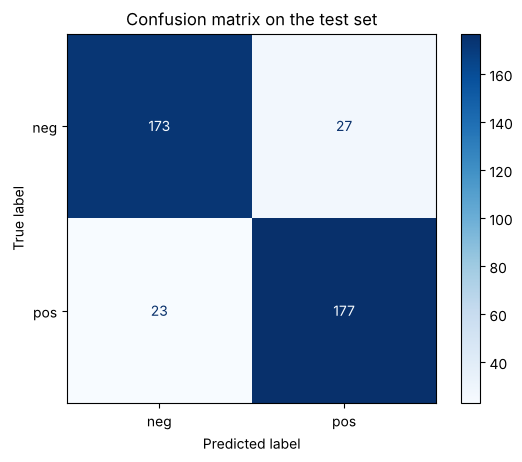

In [23]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion matrix on the test set")
plt.show()

## 8. Look inside the model

A nice property of logistic regression is that we can read its weights directly. Let's look
at the words with the most negative and most positive weights. This is a good sanity check:
if the "positive" words don't look positive, something is wrong.

In [24]:
word_weights = pd.Series(model.coef_[0], index=vectorizer.get_feature_names_out())

top_negative = word_weights.sort_values().head(15)
top_positive = word_weights.sort_values(ascending=False).head(15)

pd.DataFrame({
    "negative word": top_negative.index,
    "weight (neg)": top_negative.values.round(2),
    "positive word": top_positive.index,
    "weight (pos)": top_positive.values.round(2),
})

,negative word,weight (neg),positive word,weight (pos)
0,bad,-2.28,great,1.26
1,worst,-1.66,perfect,1.13
2,boring,-1.39,also,1.12
3,nothing,-1.27,excellent,1.09
4,script,-1.22,very,1.09
5,supposed,-1.18,life,1.01
6,plot,-1.17,best,0.97
7,have,-1.08,hilarious,0.96
8,why,-1.07,world,0.95
9,stupid,-1.07,overall,0.94


Most of these make sense: "bad", "worst", "boring", "stupid" and "waste" push towards negative,
while "great", "perfect", "excellent", "hilarious" and "terrific" push towards positive.

Some words are less obvious, like "plot", "script" and "supposed" on the negative side or
"life", "world" and "family" on the positive side. They are not sentiment words, but they
probably show up more when critics complain about a film's plot or praise its themes. The model
only learns *correlations* in its training data, so it also picks up patterns about how these
particular critics write.

It is also worth reading some reviews the model got **wrong**. `predict_proba` gives the
probability of each class; the second column is the probability of `pos` (the order matches
`model.classes_`).

In [25]:
results = test_df[["review", "sentiment"]].copy()
results["predicted"] = y_pred
results["prob_pos"] = model.predict_proba(X_test_vec)[:, 1]

mistakes = results[results["sentiment"] != results["predicted"]]
print(f"{len(mistakes)} mistakes out of {len(results)} test reviews")
print(f"P(pos) of the mistakes ranges from {mistakes['prob_pos'].min():.2f} to {mistakes['prob_pos'].max():.2f}\n")

for _, row in mistakes.head(3).iterrows():
    print(f"TRUE: {row['sentiment']} | PREDICTED: {row['predicted']} (P(pos) = {row['prob_pos']:.2f})")
    print(row["review"][:400], "...\n")

50 mistakes out of 400 test reviews
P(pos) of the mistakes ranges from 0.37 to 0.61

TRUE: neg | PREDICTED: pos (P(pos) = 0.59)
running time approximately 1hr 40mins 
reviewed by jack choo 
rating : 
the movie starts with a rather se7en-ish opening sequence , rather cool and sets the mood for things to come . 
the story propels the audience into a neo-reality ; somewhat very close to conscious reality but laced with weird tinges of blue and red . 
existenz is actually the name of a new virtual-reality game . 
supposedly ,  ...

TRUE: neg | PREDICTED: pos (P(pos) = 0.52)
in the line of duty is the critically praised series of television movies dealing with the real-life incidents that claimed lives of law enforcement officers in usa . 
the twilight murders , another one from the series , is dealing with the case of gordon kahl ( played by rod steiger ) , old farmer from north dakota who would rather spend a year in prison than pay taxes to the despised u . s . gov ...

TRUE: pos | PREDI

All the mistakes have a probability fairly close to 0.5, so when the model is wrong, it is
also unsure. Reviews often mix praise and criticism, use sarcasm, or spend most of their words
retelling the plot. A bag-of-words model only sees which words appear, not how they relate to
each other.

## 9. Try it on your own sentences

To classify new text, it must go through **exactly the same steps** as the training data:
clean → vectorize (with the *already fitted* vectorizer) → predict.

Edit the list below and re-run the cell.

In [26]:
def predict_sentiment(text):
    vec = vectorizer.transform([clean_text(text)])
    label = model.predict(vec)[0]
    prob_pos = model.predict_proba(vec)[0, 1]
    return label, prob_pos


my_reviews = [
    "An absolutely wonderful film with a brilliant cast. I loved every minute.",
    "A boring, predictable and badly acted mess.",
    "The movie was good.",
    "The movie was not good.",
    "Oh great, another two hours of my life I will never get back.",
]

for text in my_reviews:
    label, prob_pos = predict_sentiment(text)
    print(f"{label}  (P(pos) = {prob_pos:.2f})  <-  {text}")

pos  (P(pos) = 0.60)  <-  An absolutely wonderful film with a brilliant cast. I loved every minute.
neg  (P(pos) = 0.17)  <-  A boring, predictable and badly acted mess.
neg  (P(pos) = 0.39)  <-  The movie was good.
neg  (P(pos) = 0.41)  <-  The movie was not good.
pos  (P(pos) = 0.65)  <-  Oh great, another two hours of my life I will never get back.


The clearly positive and clearly negative sentences are classified correctly. The probabilities
are not very extreme, though: the model learned from reviews of about 750 words, so a single
sentence gives it few clues.

The other three results are more surprising. Let's look at the weights of a few of the words
involved:

In [27]:
word_weights[["great", "good", "not", "film", "movie"]].round(2)

great    1.26
good     0.19
not      0.09
film     0.29
movie   -0.72
dtype: float64

This explains the rest of the results:

- **"The movie was good." is classified as negative.** "good" has only a small positive weight,
  because critics use it just as often in negative reviews (for example, "good actors, terrible
  script").
  Meanwhile "movie" has a clearly negative weight: in this dataset, critics say "movie" a bit
  more often in negative reviews and "film" in positive ones. The model learns from the data,
  not from what words mean.
- **"The movie was not good."** gets the right label, but for the wrong reason. The model sees
  "not" and "good" as two separate words and cannot know that "not" flips "good". Word pairs
  (bigrams, see the exercises) can help with this.
- **Sarcasm fools the model.** "Oh great, ..." is classified as positive because of the word
  "great". Sarcasm is hard even for much more advanced models.

These limitations are why more advanced methods exist (see "Where to go next" at the end).

## 10. Putting it all together with a scikit-learn `Pipeline`

So far we ran each step by hand, which is the best way to understand them. In practice,
scikit-learn lets you chain the steps into one `Pipeline` object. It cleans, vectorizes and
classifies in a single `fit` / `predict` call, so you can't forget a step or accidentally fit
the vectorizer on test data.

`preprocessor=clean_text` tells the vectorizer to run our cleaning function first, so the
pipeline can work directly on the **raw** reviews. It should give exactly the same accuracy as
our step-by-step version.

In [28]:
pipeline = make_pipeline(
    TfidfVectorizer(preprocessor=clean_text, min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000),
)

pipeline.fit(train_df["review"], train_df["sentiment"])
pipeline_accuracy = pipeline.score(test_df["review"], test_df["sentiment"])

print(f"Pipeline accuracy: {pipeline_accuracy:.1%}")
print(pipeline.predict(["What a fantastic, moving story!"]))

Pipeline accuracy: 87.5%
['pos']


## 11. Experiment: do stop-word removal, stemming or lemmatization help?

In section 3 we decided to use only basic cleaning. Let's check that decision with data.
We build three more versions of the cleaned reviews, train the same model on each one, and
compare the test accuracy.

These functions reuse the tools from section 3. Our cleaned text has no punctuation, so
`text.split()` is enough for tokenization.

In [29]:
def remove_stop_words(text):
    return " ".join(word for word in text.split() if word not in stop_words)


def stem_text(text):
    return " ".join(stemmer.stem(word) for word in text.split())


def lemmatize_text(text):
    tagged = nltk.pos_tag(text.split())
    return " ".join(lemmatizer.lemmatize(word, to_wordnet_pos(tag)) for word, tag in tagged)


cleaned_example = clean_text(example)
print("cleaned:   ", cleaned_example)
print("stop words:", remove_stop_words(cleaned_example))
print("stemmed:   ", stem_text(cleaned_example))
print("lemmatized:", lemmatize_text(cleaned_example))

cleaned:    the plot was not good but meg ryan was amazing and the scenes in new york were better than i expected
stop words: plot good meg ryan amazing scenes new york better expected
stemmed:    the plot wa not good but meg ryan wa amaz and the scene in new york were better than i expect
lemmatized: the plot be not good but meg ryan be amazing and the scene in new york be good than i expect


The next cell takes about a minute, mostly because lemmatization has to POS-tag around
1.5 million words.

In [30]:
versions = {
    "basic cleaning only": df["clean_review"],
    "+ stop words removed": df["clean_review"].apply(remove_stop_words),
    "+ stemming": df["clean_review"].apply(stem_text),
    "+ lemmatization": df["clean_review"].apply(lemmatize_text),
}

comparison = []
for name, texts in versions.items():
    version_pipeline = make_pipeline(
        TfidfVectorizer(min_df=2, sublinear_tf=True),
        LogisticRegression(max_iter=1000),
    )
    version_pipeline.fit(texts.loc[train_df.index], y_train)  # same train/test split as before
    comparison.append({
        "preprocessing": name,
        "vocabulary size": len(version_pipeline[0].vocabulary_),  # step [0] is the vectorizer
        "test accuracy": round(version_pipeline.score(texts.loc[test_df.index], y_test), 3),
    })

pd.DataFrame(comparison)

,preprocessing,vocabulary size,test accuracy
0,basic cleaning only,22874,0.875
1,+ stop words removed,22742,0.870
2,+ stemming,15546,0.858
3,+ lemmatization,18549,0.855


None of the three steps improves accuracy. The differences from basic cleaning are only 2 to 8
test reviews out of 400, which, as mentioned, can be luck. So the honest conclusion is "no clear
improvement" rather than "they make things worse".

What they do change is the vocabulary: stemming shrinks it by about a third and lemmatization
by about a fifth, which makes the model smaller.

Why no gain? With 1,600 long training reviews, the model sees the common forms of most words
often enough to learn a weight for each one ("loved" and "loves" each get their own). Merging
them saves little, and these steps also throw information away, such as "not" or the
difference between "good" and "better". They tend to help more with small datasets, or in
tasks like search.

**The lesson:** preprocessing steps are choices to test, not rules to always follow.

## Summary

| Step | What we did | Tool |
|---|---|---|
| 1. Load | Read 2,000 labelled movie reviews | `nltk` |
| 2. Explore | Checked class balance and review length | `pandas` |
| 3. Clean & preprocess | Lowercased, removed non-letters; tried tokenization, stop words, stemming, POS tagging, lemmatization and NER | `re`, `nltk` |
| 4. Split | 80% train / 20% test, stratified | `train_test_split` |
| 5. Vectorize | Turned text into TF-IDF vectors (fit on train only!) | `TfidfVectorizer` |
| 6. Train | Learned a weight for every word | `LogisticRegression` |
| 7. Evaluate | Accuracy, classification report, confusion matrix | `sklearn.metrics` |
| 8. Interpret | Read the word weights and the mistakes | `model.coef_` |
| 9. Predict | Classified new sentences with the same steps | `predict_sentiment` |
| 10. Pipeline | Chained cleaning, vectorizing and the model into one object | `make_pipeline` |
| 11. Experiment | Tested whether stop-word removal, stemming or lemmatization help | `nltk` |

## Exercises

Change one thing at a time, re-run the notebook and compare the accuracy:

1. **Raw counts**: remove `sublinear_tf=True`. Then look again at the top words in section 8
   and at your sentences in section 9. Which words take over the positive list?
2. **Word pairs (bigrams)**: add `ngram_range=(1, 2)` so that pairs like "not good" become features.
3. **Another model**: try `MultinomialNB` from `sklearn.naive_bayes`, a classic for text.
4. **Regularization**: try `LogisticRegression(C=10, max_iter=1000)`. A larger `C` lets the
   weights grow bigger.
5. **Your own sentence**: run your own sentences through every tool in section 3. Where do the
   tagger and the NER make mistakes?

Note that the test set has only 400 reviews, so each review is worth 0.25 percentage points.
Differences of one or two points can be down to luck in the split.

## Where to go next

- **Lexicon-based sentiment** (e.g. NLTK's VADER): no training at all, just a dictionary of
  word scores. Good for short social-media text.
- **Cross-validation** (`cross_val_score`): average over several train/test splits for a more
  reliable score.
- **Word embeddings and transformers** (e.g. Hugging Face's `pipeline("sentiment-analysis")`):
  models that understand word order and context, at the cost of more compute.